In [1]:
import os

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

from idxlab.clean import clean_ticker_data
from idxlab.config import load_config
from idxlab.data import DataLoader
from idxlab.evaluation import (
    bootstrap_auc_ci,
    evaluate_classifier,
    paired_bootstrap_auc_diff,
)
from idxlab.logging_setup import setup_logging
from idxlab.split import build_dataset, time_based_split
from idxlab.backtest import proba_to_signal, run_backtest, trade_returns
from idxlab.metrics import summarize

Path("docs/results").mkdir(parents=True, exist_ok=True)
Path("docs/figures").mkdir(parents=True, exist_ok=True)

In [2]:
cfg = load_config()
setup_logging(cfg.log_level)

raw = DataLoader.from_config(cfg).load_all()
bbca = clean_ticker_data(raw["BBCA.JK"])

dataset = build_dataset(bbca, horizon=1)
splits = time_based_split(dataset, train_size=0.7, val_size=0.15)

LABEL_COLUMNS = ["forward_return", "direction"]
feature_cols = [c for c in dataset if c not in LABEL_COLUMNS]

assert len(feature_cols) == 12
assert not set(LABEL_COLUMNS) & set(feature_cols), "label bocor ke fitur!"

X_train, y_train = splits.train[feature_cols], splits.train["direction"].astype(int)
X_val, y_val = splits.val[feature_cols], splits.val["direction"].astype(int)


10:00:49 | INFO     | idxlab.data | Cache hit for BBCA.JK (data\raw\BBCA_JK.parquet)
10:00:49 | INFO     | idxlab.data | Cache hit for BBRI.JK (data\raw\BBRI_JK.parquet)
10:00:49 | INFO     | idxlab.data | Cache hit for TLKM.JK (data\raw\TLKM_JK.parquet)
10:00:49 | INFO     | idxlab.data | Cache hit for ASII.JK (data\raw\ASII_JK.parquet)
10:00:49 | INFO     | idxlab.data | Cache hit for UNVR.JK (data\raw\UNVR_JK.parquet)


In [3]:
best = json.loads(Path("docs/results/day16_best_params.json").read_text(encoding="utf-8"))

# Order matters: simplest first. This is the challenge order in the protocol.
candidates = {
    "logreg": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=42)),
    ]),
    "rf_default": RandomForestClassifier(
        n_estimators=300, max_depth=5, min_samples_leaf=10, random_state=42, n_jobs=-1
    ),
    "rf_tuned": RandomForestClassifier(**best["rf"]),
    "xgb_default": XGBClassifier(
        n_estimators=300, max_depth=3, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        eval_metric="logloss", random_state=42, n_jobs=1,
    ),
    "xgb_tuned": XGBClassifier(**best["xgb"]),
}
dummy = DummyClassifier(strategy="most_frequent")  # reference only, not a candidate

In [4]:
val_proba = {}
val_pred = {}

for name, model in {"dummy": dummy, **candidates}.items():
    model.fit(X_train, y_train)
    val_proba[name] = model.predict_proba(X_val)[:, 1]
    val_pred[name] = model.predict(X_val)

In [5]:
chosen = "logreg"      

returns_all = bbca["Close"].pct_change()
val_returns = returns_all.loc[X_val.index]

proba_val = pd.Series(val_proba[chosen], index=X_val.index)

# cek cepat: tidak boleh ada NaN, dan panjangnya harus sama
assert val_returns.notna().all()
assert len(val_returns) == len(proba_val)

In [6]:
signal = proba_to_signal(proba_val, threshold=0.5)
daily = run_backtest(val_returns, signal)             # biaya default 0.15% / 0.25%, lag=1
summary = summarize(daily)
summary.round(4).to_frame("BBCA.JK (val)")

,BBCA.JK (val)
cum_return,-0.0378
sharpe,-0.5633
max_drawdown,-0.0961
win_rate,0.2500
n_trades,4.0000
exposure,0.1890
total_cost,0.0160
bench_cum_return,-0.1116
bench_sharpe,-0.6438
bench_max_drawdown,-0.2077


In [8]:
print(Path.cwd())

c:\Semester 7\Project Iseng\IDX-ML-Lab


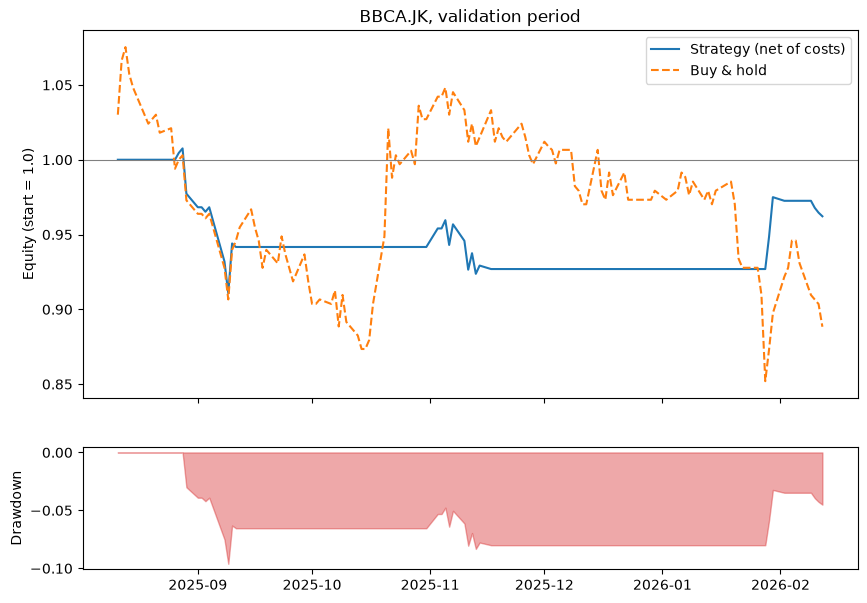

In [9]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1]})

ax1.plot(daily.index, daily["equity"], label="Strategy (net of costs)")
ax1.plot(daily.index, daily["benchmark_equity"], label="Buy & hold", linestyle="--")
ax1.axhline(1.0, color="grey", linewidth=0.8)
ax1.set_ylabel("Equity (start = 1.0)")
ax1.set_title("BBCA.JK, validation period")
ax1.legend()

# drawdown strategi: jarak equity ke puncaknya
drawdown = daily["equity"] / daily["equity"].cummax() - 1             
ax2.fill_between(daily.index, drawdown, 0, alpha=0.4, color="tab:red")
ax2.set_ylabel("Drawdown")

fig_dir = Path("docs/figures")
fig_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(fig_dir / "day20_equity_curve.png", dpi=150)
plt.show()

In [10]:
n_days = len(signal)
n_long = int(signal.sum())
rng = np.random.default_rng(42)

random_cum = []
for _ in range(500):
    pick = rng.choice(n_days, size=n_long, replace=False)
    fake = np.zeros(n_days, dtype=int)
    fake[pick] = 1
    fake_signal = pd.Series(fake, index=signal.index)
    random_cum.append(summarize(run_backtest(val_returns, fake_signal))["cum_return"])

print(f"Strategi model : {summary['cum_return']:.2%}")
print(f"Acak (median)  : {np.median(random_cum):.2%}")
print(f"Acak 5%-95%    : {np.percentile(random_cum, 5):.2%} .. {np.percentile(random_cum, 95):.2%}")
print(f"Model lebih baik dari {np.mean(summary['cum_return'] > np.array(random_cum)):.0%} sinyal acak")

Strategi model : -3.78%
Acak (median)  : -10.14%
Acak 5%-95%    : -22.31% .. 3.65%
Model lebih baik dari 82% sinyal acak


In [11]:
rows = {}
for th in [0.45, 0.50, 0.55]:
    d = run_backtest(val_returns, proba_to_signal(proba_val, th))
    rows[th] = summarize(d)[["cum_return", "sharpe", "max_drawdown", "n_trades", "exposure"]]
pd.DataFrame(rows).round(3)

,0.45,0.50,0.55
cum_return,-0.050,-0.038,-0.028
sharpe,-0.473,-0.563,-0.572
max_drawdown,-0.112,-0.096,-0.042
n_trades,11.000,4.000,6.000
exposure,0.323,0.189,0.118
